In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.svm import SVR

from sklearn.tree import DecisionTreeRegressor

import config
import data

In [2]:
import sys
print(sys.executable)

c:\universidad\ejercicio_dataset\ejemplo-uso-mlflow\venv\Scripts\python.exe


In [3]:
import sys
print(sys.executable)

c:\universidad\ejercicio_dataset\ejemplo-uso-mlflow\venv\Scripts\python.exe


Cargar los datos

In [4]:
crudo = data._leer_csv()
print(config.DATA_PATH.name, crudo.shape)
crudo.head()

car_details_v4.csv (2059, 20)


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [5]:
crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   str    
 1   Model               2059 non-null   str    
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   str    
 6   Transmission        2059 non-null   str    
 7   Location            2059 non-null   str    
 8   Color               2059 non-null   str    
 9   Owner               2059 non-null   str    
 10  Seller Type         2059 non-null   str    
 11  Engine              1979 non-null   str    
 12  Max Power           1979 non-null   str    
 13  Max Torque          1979 non-null   str    
 14  Drivetrain          1923 non-null   str    
 15  Length              1995 non-null   float64
 16  Width            

Nulos y duplicados

In [6]:
print(crudo.isnull().sum()[crudo.isnull().sum() > 0])
print("Duplicados:", crudo.duplicated().sum())

Engine                 80
Max Power              80
Max Torque             80
Drivetrain            136
Length                 64
Width                  64
Height                 64
Seating Capacity       64
Fuel Tank Capacity    113
dtype: int64
Duplicados: 0


Hay nulos en Engine, Max Power, Max Torque, Drivetrain, medidas y tanque. Se rellenan con la mediana (numéricas) y la moda (categóricas). No hay duplicados.

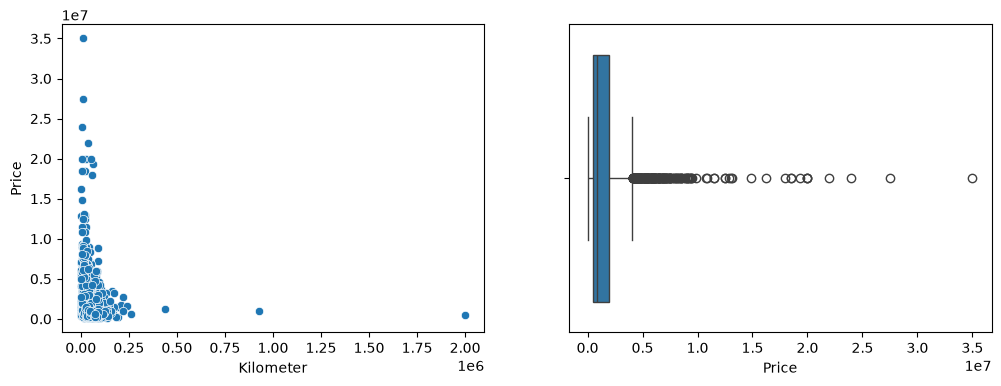

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=crudo, x="Kilometer", y="Price", ax=ejes[0])
sns.boxplot(x=crudo["Price"], ax=ejes[1])
plt.show()

Hay kilometrajes muy altos y precios extremos. Se filtran Kilometer > 500000 y precios sobre el cuantil 0.99 (ver config.py).

Markdown: 4. Variable objetivo

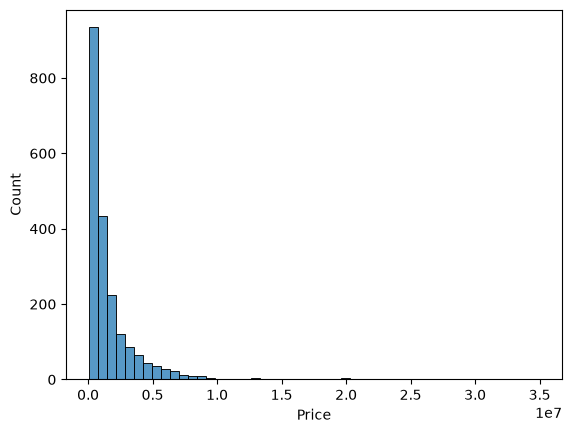

count    2.059000e+03
mean     1.702992e+06
std      2.419881e+06
min      4.900000e+04
25%      4.849990e+05
50%      8.250000e+05
75%      1.925000e+06
max      3.500000e+07
Name: Price, dtype: float64

In [8]:
sns.histplot(crudo["Price"], bins=50)
plt.show()
crudo["Price"].describe()

Markdown: 5. Limpieza y correlación

{'archivo': 'car_details_v4.csv', 'filas_leidas': 2059, 'columnas_leidas': ['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity'], 'filas_duplicadas': 0, 'columnas_eliminadas': ['Model'], 'nulos_imputados': 745, 'filas_km_excesivo': 2, 'km_max': 500000, 'filas_precio_extremo': 21, 'tope_precio': 10844000.000000006, 'filas_limpias': 2036}


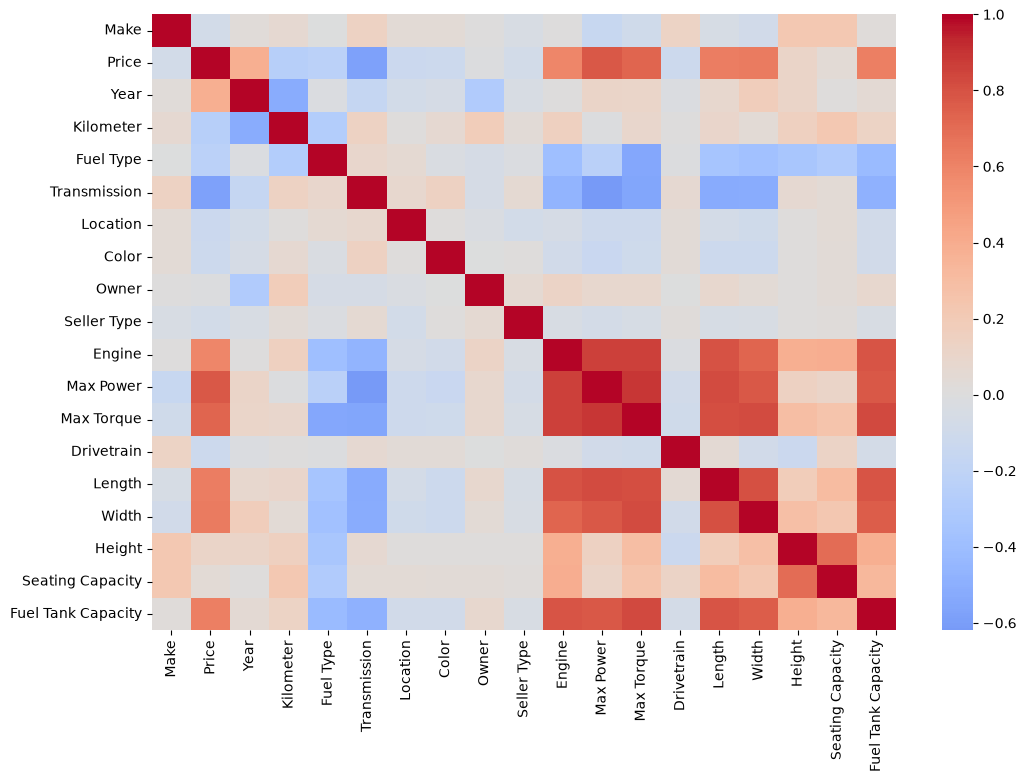

Price                 1.000000
Max Power             0.774517
Max Torque            0.725367
Width                 0.635757
Length                0.624133
Fuel Tank Capacity    0.620308
Engine                0.592659
Year                  0.390530
Height                0.108341
Seating Capacity      0.042661
Owner                -0.007657
Seller Type          -0.079298
Make                 -0.080419
Drivetrain           -0.113736
Color                -0.121805
Location             -0.129867
Fuel Type            -0.228362
Kilometer            -0.254930
Transmission         -0.577673
Name: Price, dtype: float64

In [9]:
limpio, resumen = data._limpiar(crudo)
print(resumen)
codificado = limpio.copy()
for col in config.CATEGORICAS:
    codificado[col] = codificado[col].astype("category").cat.codes
plt.figure(figsize=(12, 8))
sns.heatmap(codificado.corr(), cmap="coolwarm", center=0)
plt.show()
codificado.corr()["Price"].sort_values(ascending=False)

Markdown: 6. Preprocesar y partir

In [10]:
x_train, x_test, y_train, y_test, preprocesador, material = data.cargar_particion()
print(x_train.shape, x_test.shape)
x_train.head()

(1425, 18) (611, 18)


,Make,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
730,27,1.371102,0.207326,2,0,10,15,1,2,1.860732,0.831767,1.568417,0,1.211721,0.682556,1.842443,2.123896,1.974263
1798,27,-1.610064,1.700241,6,1,45,15,3,2,0.220421,0.096274,-0.528707,1,0.617273,-0.042769,-0.826336,-0.377841,0.236470
836,7,-0.119481,0.243308,2,1,29,15,1,2,-0.458917,-0.656731,-0.154221,1,-0.676525,-0.241279,-0.638394,-0.377841,-0.458648
857,19,0.774869,-0.615301,2,0,45,15,1,2,0.486694,1.146979,1.193931,2,0.957623,0.338981,-1.112009,-0.377841,1.001099
575,15,0.774869,-1.425741,2,0,15,13,1,2,-0.288229,-0.218937,0.220266,1,-1.058837,-0.294724,-1.322504,-0.377841,-0.528159


Markdown: 7. Modelos

In [11]:
modelos = {
    "regresion_lineal": LinearRegression(),
    "svr": SVR(C=1e7),
    "arbol_decision": DecisionTreeRegressor(random_state=config.RANDOM_SEED),
    "random_forest": RandomForestRegressor(random_state=config.RANDOM_SEED),
}
filas = []
for nombre, modelo in modelos.items():
    modelo.fit(x_train, y_train)
    pred = modelo.predict(x_test)
    filas.append({
        "modelo": nombre,
        "r2": r2_score(y_test, pred),
        "mae": mean_absolute_error(y_test, pred),
    })
resultados = pd.DataFrame(filas).sort_values("r2", ascending=False)
resultados

,modelo,r2,mae
3,random_forest,0.898786,249158.910182
2,arbol_decision,0.761516,362255.312602
0,regresion_lineal,0.698243,564489.482138
1,svr,0.682820,472782.662014


Markdown: Conclusión

- **Objetivo:** `Price`.
- **Métrica:** R2 (también se mira MAE). `register.py` elige el run con mayor R2.
- **Features:** las 18 columnas que entrega `data.py`, codificadas y escaladas.
- **Limpieza:** se descarta `Model`, se extrae el número de Engine, Max Power y Max Torque, se imputan nulos y se filtran kilometrajes y precios atípicos.
- **Resultado:** el mejor modelo fue random_forest (R2 ≈ 0.90, MAE ≈ 249,000), que queda como `challenger`.

In [12]:
import pandas as pd # manejo de datos
import matplotlib.pyplot as plt # graficos
from sklearn.model_selection import train_test_split # division de datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler # preprocesamiento de datos
# importar modelos de clasificacion
from sklearn.linear_model import LogisticRegression # regresion logistica
from sklearn.svm import SVC # maquinas de soporte vectorial
from sklearn.tree import DecisionTreeClassifier # arboles de decision
from sklearn.ensemble import RandomForestClassifier # random forest
# importar metricas
from sklearn.metrics import accuracy_score # Metrica para clasificacion
import joblib
import json